# Section 6: Time Series Clustering on ECG Data

**What you'll learn**
- Load heartbeat recordings from the UCR archive with aeon
- See why Euclidean distance fails on shifted signals
- Compare Euclidean, shape-based and DTW distances on one beat
- Cluster beats with k-means, k-Shape and HDBSCAN
- Grade every clustering against held-back labels with ARI

## Setup
- Slides 1-2

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from aeon.datasets import load_classification
from aeon.distances import euclidean_distance, sbd_distance, dtw_distance
from aeon.clustering import KShape
from sklearn.cluster import KMeans, HDBSCAN
from sklearn.metrics import adjusted_rand_score

## Part 1: ECGFiveDays
- Slides 3-4
- 884 heartbeats from one patient, recorded five days apart
- Each beat is 136 readings long
- The label `y` says which day; it is only used for grading

In [2]:
X, y = load_classification("ECGFiveDays")
X.shape

(884, 1, 136)

In [3]:
pd.Series(y).value_counts()

1    442
2    442
Name: count, dtype: int64

- aeon keeps series as (beats, channels, readings); one channel here

In [4]:
beats = X[:, 0]
beats.shape

(884, 136)

## Looking at the Beats
- Slide 5

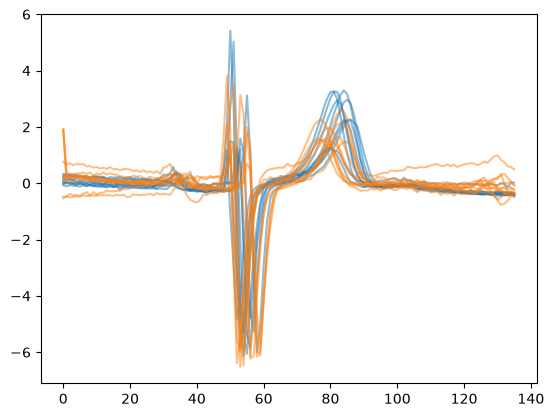

In [5]:
for day, colour in [("1", "tab:blue"), ("2", "tab:orange")]:
    plt.plot(beats[y == day][:10].T, color=colour, alpha=0.5)
plt.show()

- UCR series are already z-normalised: every beat has mean 0 and standard deviation 1

In [6]:
beats.mean(axis=1).round(2).max(), beats.std(axis=1).round(2).min()

(np.float64(-0.0), np.float64(1.0))

## Three Distances on One Beat
- Slides 6-8
- Shift a beat 10 readings to the right; the shape is unchanged

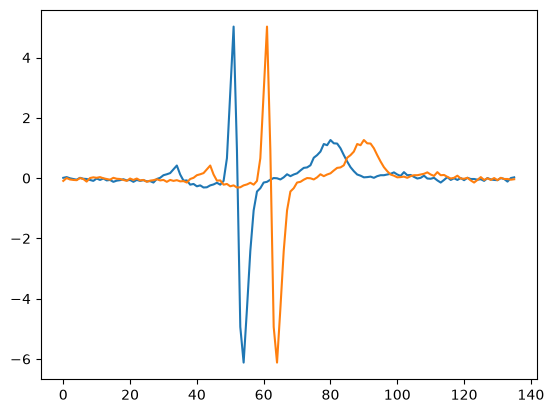

In [7]:
beat = beats[0]
shifted = np.roll(beat, 10)
plt.plot(beat)
plt.plot(shifted)
plt.show()

- Euclidean: the shifted copy looks further away than a different beat

In [8]:
euclidean_distance(beat, shifted), euclidean_distance(beat, beats[5])

(16.203587172502072, 12.579889024156774)

- Shape-based distance (SBD): slide one series over the other, keep the best match

In [9]:
sbd_distance(beat, shifted), sbd_distance(beat, beats[5])

(0.00024972807811496356, 0.05844443628152063)

- Dynamic time warping (DTW): stretch time locally to line the series up

In [10]:
dtw_distance(beat, shifted), dtw_distance(beat, beats[5])

(0.040367421749493086, 11.46094191117133)

## k-Means on Raw Readings
- Slide 9

In [11]:
kmeans_labels = KMeans(2).fit_predict(beats)
adjusted_rand_score(y, kmeans_labels)

-0.00039565649764004737

In [12]:
pd.crosstab(kmeans_labels, y)

col_0,1,2
row_0,,
0,212,224
1,230,218


## k-Shape
- Slide 10
- k-means with SBD as the distance and a shape-aware centroid

In [13]:
kshape = KShape(n_clusters=2)
kshape_labels = kshape.fit_predict(X)
adjusted_rand_score(y, kshape_labels)

0.7943686685405551

In [14]:
pd.crosstab(kshape_labels, y)

col_0,1,2
row_0,,
0,394,0
1,48,442


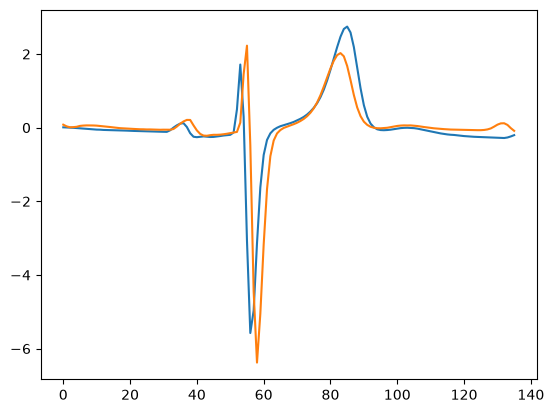

In [15]:
plt.plot(kshape.cluster_centres_[:, 0].T)
plt.show()

## HDBSCAN on Raw Readings
- Slide 11
- `copy=True` stops HDBSCAN changing the input in place

In [16]:
hdbscan_labels = HDBSCAN(copy=True).fit_predict(beats)
adjusted_rand_score(y, hdbscan_labels)

0.17427888167277

- Number of clusters, and the share of beats called noise

In [17]:
hdbscan_labels.max() + 1, (hdbscan_labels == -1).mean()

(np.int64(31), np.float64(0.24547511312217193))

## Part 2: ECG5000
- Slide 12
- 5,000 beats from one patient with heart failure, 140 readings each
- Five classes: one normal, four kinds of abnormal beat

In [18]:
X, y = load_classification("ECG5000")
beats = X[:, 0]
X.shape

(5000, 1, 140)

In [19]:
pd.Series(y).value_counts()

1    2919
2    1767
4     194
3      96
5      24
Name: count, dtype: int64

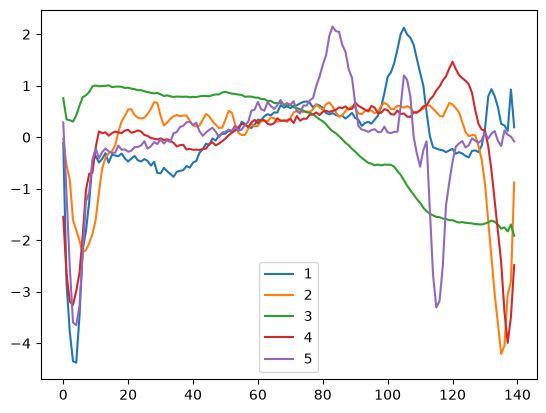

In [20]:
for label in ["1", "2", "3", "4", "5"]:
    plt.plot(beats[y == label][0], label=label)
plt.legend()
plt.show()

## Three Methods on ECG5000
- Slide 13

In [21]:
results = {"k-means": adjusted_rand_score(y, KMeans(5).fit_predict(beats))}
results["k-means"]

0.4839730215820551

In [22]:
results["k-Shape"] = adjusted_rand_score(y, KShape(n_clusters=5).fit_predict(X))
results["k-Shape"]

0.5083554495845555

In [23]:
hdbscan_labels = HDBSCAN(copy=True).fit_predict(beats)
results["HDBSCAN"] = adjusted_rand_score(y, hdbscan_labels)
results["HDBSCAN"]

0.7763347430668504

In [24]:
pd.crosstab(hdbscan_labels, y)

col_0,1,2,3,4,5
row_0,,,,,
-1,217,80,36,38,20
0,0,7,0,0,0
1,38,0,0,0,0
2,0,2,3,0,0
3,1,1553,52,98,2
4,0,107,4,0,0
5,8,0,0,0,0
6,2655,1,1,2,2
7,0,17,0,56,0


## Comparing the Methods
- Slide 14

In [25]:
pd.Series(results)

k-means    0.483973
k-Shape    0.508355
HDBSCAN    0.776335
dtype: float64

## Lab: Normal vs Abnormal
- Grade a two-cluster k-Shape against "normal or not"
- Then try k-means with two clusters on the same question

In [26]:
normal = y == "1"
adjusted_rand_score(normal, KShape(n_clusters=2).fit_predict(X))

0.7747801350981267

## Wrap-Up
- Slides 15-18